# Multiple Regression and Regional Classification | Washington Housing Analysis

**Research questions**

2. **Unemployment rate:** Is the unemployment rate significantly associated with home values in Washington State?
3. **Multiple regression:** Which of median income, unemployment rate and mortgage interest rate have statistically significant associations with home values after adjusting for the others?
4. **Regional classification:** Does including the WSDOT region improve the explanatory performance of the regression beyond income, unemployment and mortgage rates?

Question 1 (median income alone) is in `03_statistical_analysis_Giang.ipynb`.

All results describe **association, not causation**. The outcome is `log(average ZHVI)`, and standard errors are clustered by county unless stated otherwise (the same repeated-county problem explained in notebook 03).

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from pathlib import Path

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})

CANDIDATES = [Path("../data/housing_final.csv"), Path("data/housing_final.csv"), Path("housing_final.csv")]
final_dataset_path = next((p for p in CANDIDATES if p.exists()), None)
if final_dataset_path is None:
    raise FileNotFoundError(f"housing_final.csv not found. Current folder: {Path.cwd()}. Put the file in one of: {[str(p) for p in CANDIDATES]}")
print("Reading", final_dataset_path.resolve())

df = pd.read_csv(final_dataset_path, dtype={"county_fips": str})

In [3]:
model_df = df.dropna(subset=["average_zhvi", "median_income"]).copy()      # drops Columbia County 2015 (missing ZHVI)
model_df["log_zhvi"] = np.log(model_df["average_zhvi"])
model_df["log_income"] = np.log(model_df["median_income"])
print(model_df.shape)

(389, 10)


---
## 1. Relationship between Home Value and Unemployment Rate

### Research Question
Is the county unemployment rate significantly associated with county-level home values in Washington State?

$H_0$: The regression coefficient for the unemployment rate equals zero $(\beta_1 = 0)$.

$H_A$: The regression coefficient for the unemployment rate does not equal zero $(\beta_1 \ne 0)$.

### Method
OLS on `log(home value)`, with standard errors clustered by county. Because unemployment is measured in percentage points, the coefficient (times 100) is the approximate **percent change in home value for a 1 percentage point higher unemployment rate**. As in notebook 03 we fit three versions: pooled (Model U1), with county fixed effects (U2), and with county and year fixed effects (U3). U3 asks whether a county's home values change when **its own** unemployment rate moves, after removing anything that changed for all counties in the same year (for example the 2020 shock).

In [6]:
def fit(formula, data=model_df):
    """OLS with standard errors clustered by county."""
    return smf.ols(formula, data).fit(cov_type="cluster", cov_kwds={"groups": data["county_fips"]})

def pct(b):                       # coefficient on a log outcome -> exact percent change
    return (np.exp(b) - 1) * 100

u1 = fit("log_zhvi ~ unemployment_rate")
u2 = fit("log_zhvi ~ unemployment_rate + C(county_fips)")
u3 = fit("log_zhvi ~ unemployment_rate + C(county_fips) + C(year)")

rows = []
for name, m in [("U1: pooled", u1), ("U2: + county FE", u2), ("U3: + county & year FE", u3)]:
    lo, hi = m.conf_int().loc["unemployment_rate"]
    rows.append({"model": name, "coef": m.params["unemployment_rate"], "SE": m.bse["unemployment_rate"], "p-value": m.pvalues["unemployment_rate"],
                 "95% CI": f"[{lo:.3f}, {hi:.3f}]", "% change in value per +1 pp": pct(m.params["unemployment_rate"]), "R-squared": m.rsquared})
pd.DataFrame(rows).set_index("model").round(4)

,coef,SE,p-value,95% CI,% change in value per +1 pp,R-squared
model,,,,,,
U1: pooled,-0.1243,0.0161,0.0000,"[-0.156, -0.093]",-11.6867,0.2312
U2: + county FE,-0.1116,0.0113,0.0000,"[-0.134, -0.089]",-10.5591,0.6801
U3: + county & year FE,-0.0088,0.0080,0.2722,"[-0.025, 0.007]",-0.8786,0.9915


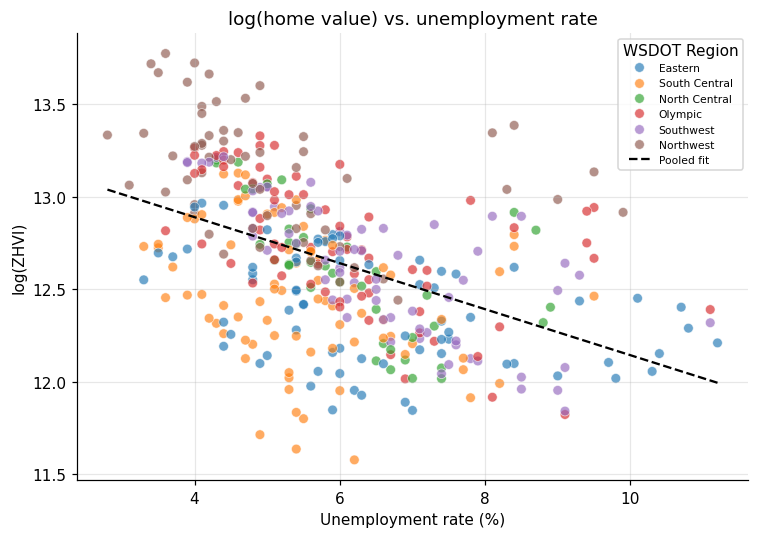

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=model_df, x="unemployment_rate", y="log_zhvi", hue="wsdot_region", alpha=0.65, s=40, ax=ax)
xs = np.linspace(model_df["unemployment_rate"].min(), model_df["unemployment_rate"].max(), 50)
ax.plot(xs, u1.params["Intercept"] + u1.params["unemployment_rate"] * xs, "k--", label="Pooled fit")
ax.set(title="log(home value) vs. unemployment rate", xlabel="Unemployment rate (%)", ylabel="log(ZHVI)"); ax.legend(fontsize=7, title="WSDOT Region")
plt.tight_layout(); plt.show()

* **Pooled (U1):** the coefficient is about -0.124 (p < 0.001): a 1 percentage point higher unemployment rate is associated with an approximately **11.7% lower** home value. We reject $H_0$. Unemployment alone explains 23% of the variation in log home value.
* **County fixed effects (U2):** the association stays about the same (-0.112, about -10.6% per point, p < 0.001), so within a county, years with higher unemployment have lower home values.
* **County and year fixed effects (U3):** the coefficient shrinks to -0.009 (p = 0.27) and is **not** significant. Once we remove what is common to all counties in a year, a county's own unemployment no longer predicts its home values. The earlier relationship therefore largely reflects the **shared time pattern**: unemployment spiked in 2020 and then fell while home values kept rising.
* **Answer to question 2:** unemployment is significantly associated with home values when we compare counties or look at a county over time, but not once year effects are removed. We should not interpret it as an independent effect.

---
## 2. Multiple regression: income, unemployment and mortgage rate

### Research Question
Which of median household income, unemployment rate and the mortgage interest rate have statistically significant associations with home values after adjusting for the other predictors?

$H_0$: $\beta_j = 0$ for predictor $j$, holding the other predictors fixed. $H_A$: $\beta_j \ne 0$.

### Model
$\log(\text{ZHVI}) = \beta_0 + \beta_1 \log(\text{income}) + \beta_2 \text{unemployment} + \beta_3 \text{mortgage rate} + \varepsilon$

We check multicollinearity first, then fit three versions: pooled (M1), with county fixed effects (M2) and with county and year fixed effects (M3). In M3 the mortgage rate cannot be estimated, because it is a national rate with a single value per year and the year effects absorb it.

In [11]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

predictors = ["log_income", "unemployment_rate", "mortgage_rate_mean"]
print("Correlation matrix:"); print(model_df[["log_zhvi"] + predictors].corr().round(2).to_string())
X = model_df[predictors].assign(const=1.0)
print("\nVariance inflation factors (above ~5 would be a concern):")
print(pd.Series({c: variance_inflation_factor(X.values, i) for i, c in enumerate(X.columns) if c != "const"}).round(2).to_string())

Correlation matrix:
                    log_zhvi  log_income  unemployment_rate  mortgage_rate_mean
log_zhvi                1.00        0.85              -0.48                0.39
log_income              0.85        1.00              -0.53                0.47
unemployment_rate      -0.48       -0.53               1.00               -0.48
mortgage_rate_mean      0.39        0.47              -0.48                1.00

Variance inflation factors (above ~5 would be a concern):
log_income            1.52
unemployment_rate     1.54
mortgage_rate_mean    1.43


In [12]:
m1 = fit("log_zhvi ~ log_income + unemployment_rate + mortgage_rate_mean")
m2 = fit("log_zhvi ~ log_income + unemployment_rate + mortgage_rate_mean + C(county_fips)")
m3 = fit("log_zhvi ~ log_income + unemployment_rate + C(county_fips) + C(year)")

def coef_table(models, terms=("log_income", "unemployment_rate", "mortgage_rate_mean")):
    out = {}
    for name, m in models.items():
        col = {}
        for t in terms:
            if t in m.params:
                stars = "***" if m.pvalues[t] < 0.01 else "**" if m.pvalues[t] < 0.05 else "*" if m.pvalues[t] < 0.1 else ""
                col[t] = f"{m.params[t]:.4f}{stars}  (SE {m.bse[t]:.4f}, p={m.pvalues[t]:.3f})"
            else:
                col[t] = "not estimable"
        col["R-squared"] = f"{m.rsquared:.3f}"; col["Adj. R-squared"] = f"{m.rsquared_adj:.3f}"; col["N"] = int(m.nobs)
        out[name] = col
    return pd.DataFrame(out)

print("*** p<0.01, ** p<0.05, * p<0.1; cluster-robust standard errors")
coef_table({"M1: pooled": m1, "M2: + county FE": m2, "M3: + county & year FE": m3})

*** p<0.01, ** p<0.05, * p<0.1; cluster-robust standard errors


,M1: pooled,M2: + county FE,M3: + county & year FE
log_income,"1.5158*** (SE 0.1139, p=0.000)","1.8432*** (SE 0.0722, p=0.000)","0.0622 (SE 0.1524, p=0.683)"
unemployment_rate,"-0.0137 (SE 0.0187, p=0.463)","-0.0223*** (SE 0.0030, p=0.000)","-0.0087 (SE 0.0079, p=0.274)"
mortgage_rate_mean,"-0.0102 (SE 0.0104, p=0.329)","-0.0423*** (SE 0.0066, p=0.000)",not estimable
R-squared,0.725,0.968,0.992
Adj. R-squared,0.723,0.964,0.990
N,389,389,389


In [13]:
# Percent change in home value for a meaningful change in each predictor (M2, county fixed effects)
b = m2.params
print(f"+1% income:                     {b['log_income']:.2f}% change in home value")
print(f"+1 pp unemployment rate:        {pct(b['unemployment_rate']):.1f}% change in home value")
print(f"+1 pp mortgage rate:            {pct(b['mortgage_rate_mean']):.1f}% change in home value")

# Joint test that unemployment and the mortgage rate add nothing beyond income (M1)
print("\nPooled model, joint test that unemployment and mortgage rate both equal 0:")
print(m1.wald_test("unemployment_rate = 0, mortgage_rate_mean = 0", use_f=True, scalar=True))

+1% income:                     1.84% change in home value
+1 pp unemployment rate:        -2.2% change in home value
+1 pp mortgage rate:            -4.1% change in home value

Pooled model, joint test that unemployment and mortgage rate both equal 0:
<F test: F=0.49019535492771893, p=0.6163263940875203, df_denom=38, df_num=2>


**Reading the results**
* **Pooled (M1):** only **median income** is significant (coefficient 1.52, p < 0.001). Unemployment (p = 0.46) and the mortgage rate (p = 0.33) are not significant once income is in the model. Unemployment was significant alone in Section 1, which means it was mostly standing in for income and for the difference between counties: counties with high unemployment also have low incomes. The variance inflation factors (all about 1.5) show multicollinearity is not a concern.
* **County fixed effects (M2):** all three are significant. Within a county, a 1% higher income goes with about 1.84% higher home values, a 1 percentage point higher unemployment rate with about 2.2% lower values, and a 1 point higher mortgage rate with about 4.1% lower values (all p < 0.01).
* **County and year fixed effects (M3):** none of the estimable predictors are significant: income 0.06 (p = 0.68) and unemployment -0.009 (p = 0.27). Once we remove what is common to all counties each year, a county's own income and unemployment no longer explain its home values. The mortgage rate cannot be estimated.
* **Answer to question 3:** **Median income** is the most robust predictor: significant in the pooled and county fixed effects models. **Unemployment and mortgage rates** are significant only with county fixed effects, and their estimates are tied to the time trend: the mortgage rate has just 10 distinct values, so we cannot separate it from everything else that changed from year to year. We cannot claim any of the three has an effect independent of the time trend.

---
## 3. Does the WSDOT region improve the model?

### Research Question
Does adding the WSDOT region improve the explanatory performance of the regression beyond median income, unemployment rate and mortgage interest rate?

### Method
We compare nested models. The **baseline** is the pooled model M1. The **region model** adds five WSDOT region indicators (Northwest is the reference group). We judge the improvement four ways:

1. **Fit:** adjusted R-squared, AIC and BIC (lower AIC/BIC is better).
2. **A test of the five region coefficients.** The usual F-test assumes independent rows, which is not true here, so we also report a **cluster-robust Wald test**, which is the one we rely on.
3. **Leave-one-county-out prediction:** fit without a county and predict it. This tests whether region helps predict a county the model has not seen.
4. **Time hold-out:** train on 2015-2022 and test on 2023-2024.

As a ceiling, we also fit county fixed effects, which give every county its own intercept. Region is a coarser version of this.

In [17]:
base = "log_zhvi ~ log_income + unemployment_rate + mortgage_rate_mean"
REGION = "C(wsdot_region, Treatment('Northwest'))"

ols = lambda f, d=model_df: smf.ols(f, d).fit()
base_m, region_m, county_m = ols(base), ols(base + " + " + REGION), ols(base + " + C(county_fips)")

fit_table = pd.DataFrame({
    name: {"R-squared": m.rsquared, "Adj. R-squared": m.rsquared_adj, "AIC": m.aic, "BIC": m.bic, "Predictors (df)": int(m.df_model)}
    for name, m in {"Baseline (3 predictors)": base_m, "+ WSDOT region": region_m, "+ county FE (ceiling)": county_m}.items()
})
fit_table.round(3)

,Baseline (3 predictors),+ WSDOT region,+ county FE (ceiling)
R-squared,0.725,0.786,0.968
Adj. R-squared,0.723,0.781,0.964
AIC,-68.026,-155.563,-825.919
BIC,-52.171,-119.891,-659.449
Predictors (df),3.000,8.000,41.000


In [18]:
# 1) Ordinary nested F-test (assumes independent rows, so the p-value is too optimistic)
F, p, df_diff = region_m.compare_f_test(base_m)
print(f"Ordinary F-test, region vs baseline:           F = {F:.2f}, p = {p:.2g}")

# 2) Cluster-robust Wald test of the five region coefficients (our main test)
rc = fit(base + " + " + REGION)
region_terms = [n for n in rc.params.index if "wsdot_region" in n]
R = np.zeros((len(region_terms), len(rc.params)))
for i, n in enumerate(region_terms): R[i, list(rc.params.index).index(n)] = 1
wald = rc.wald_test(R, use_f=True, scalar=True)
print(f"Cluster-robust Wald test, region coefficients: F = {float(wald.statistic):.2f}, p = {float(wald.pvalue):.3f}")

F2, p2, _ = county_m.compare_f_test(region_m)
print(f"County FE vs region (ordinary F-test):         F = {F2:.1f}, p = {p2:.2g}")

print("\nRegion effects relative to Northwest (log points, cluster-robust):")
tab = pd.DataFrame({"coef": rc.params[region_terms], "SE": rc.bse[region_terms], "p": rc.pvalues[region_terms]})
tab.index = [n.split("[T.")[1].rstrip("]") for n in tab.index]
tab["% difference"] = pct(tab["coef"])
tab.round(3)

Ordinary F-test, region vs baseline:           F = 21.66, p = 4.4e-19
Cluster-robust Wald test, region coefficients: F = 2.32, p = 0.062
County FE vs region (ordinary F-test):         F = 59.3, p = 3.8e-122

Region effects relative to Northwest (log points, cluster-robust):


,coef,SE,p,% difference
Eastern,-0.242,0.110,0.028,-21.522
North Central,-0.186,0.115,0.105,-17.002
Olympic,-0.159,0.104,0.126,-14.707
South Central,-0.366,0.116,0.002,-30.669
Southwest,-0.169,0.091,0.063,-15.556


In [19]:
# 3) Leave-one-county-out prediction: how well does each model predict a county it has never seen?
rows = {"Baseline": [], "+ WSDOT region": []}
for fips in model_df["county_fips"].unique():
    tr, te = model_df[model_df["county_fips"] != fips], model_df[model_df["county_fips"] == fips]
    for name, f in [("Baseline", base), ("+ WSDOT region", base + " + " + REGION)]:
        pred = ols(f, tr).predict(te)
        rows[name].append({"fips": fips, "mape": ((np.exp(pred) - te["average_zhvi"]).abs() / te["average_zhvi"]).mean() * 100, "sq_err": ((pred - te["log_zhvi"]) ** 2).mean()})
loco = pd.DataFrame({
    n: {"MAPE (%)": np.mean([r["mape"] for r in v]), "RMSE (log)": np.sqrt(np.mean([r["sq_err"] for r in v]))} for n, v in rows.items()
}).T
improved = sum(r2["mape"] < r1["mape"] for r1, r2 in zip(rows["Baseline"], rows["+ WSDOT region"]))
print(f"Leave-one-county-out ({model_df['county_fips'].nunique()} counties). Region improves the error for {improved} of {model_df['county_fips'].nunique()} counties.")
loco.round(3)

Leave-one-county-out (39 counties). Region improves the error for 12 of 39 counties.


,MAPE (%),RMSE (log)
Baseline,17.528,0.230
+ WSDOT region,17.665,0.225


In [20]:
# 4) Time hold-out: train 2015-2022, test 2023-2024
tr, te = model_df[model_df["year"] <= 2022], model_df[model_df["year"] >= 2023]
out = {}
for name, f in [("Baseline", base), ("+ WSDOT region", base + " + " + REGION), ("+ county FE", base + " + C(county_fips)")]:
    pred = ols(f, tr).predict(te)
    out[name] = {"MAPE (%)": ((np.exp(pred) - te["average_zhvi"]).abs() / te["average_zhvi"]).mean() * 100, "RMSE (log)": np.sqrt(((pred - te["log_zhvi"]) ** 2).mean())}
naive = (te["average_zhvi"] - te["county_fips"].map(tr[tr["year"] == 2022].set_index("county_fips")["average_zhvi"])).abs() / te["average_zhvi"]
out["Naive (2022 value carried forward)"] = {"MAPE (%)": naive.mean() * 100, "RMSE (log)": np.nan}
pd.DataFrame(out).T.round(3)

,MAPE (%),RMSE (log)
Baseline,15.899,0.203
+ WSDOT region,12.226,0.169
+ county FE,10.567,0.125
Naive (2022 value carried forward),2.330,NaN


**Reading the results**
* **Fit improves.** Adding region raises adjusted R-squared from 0.723 to 0.781 and lowers AIC from -68 to -156 and BIC from -52 to -120, so it fits better even after penalizing the five extra parameters. Region differences are large: relative to Northwest, South Central counties have about 31% lower home values (p = 0.002) and Eastern counties about 21% lower (p = 0.03), while the others are not individually significant.
* **Significance depends on the test.** The ordinary F-test gives p < 0.001, but it treats the 389 rows as independent. The cluster-robust Wald test, which accounts for repeated counties, gives **p = 0.062**: borderline, not significant at 0.05. With only 39 counties, we have limited evidence that region matters once we account for this.
* **It does not help predict a new county.** In leave-one-county-out prediction, adding region leaves the error essentially unchanged (MAPE 17.5% for the baseline vs. 17.7% with region; RMSE on the log scale 0.230 vs. 0.225), and it helps for only 12 of 39 counties. The region effects are estimated from the other counties in each region, and counties within a region differ a lot.
* **It helps a little over time.** In the time hold-out, region reduces the error (15.9% to 12.2%), but county fixed effects do better (10.6%), and carrying each county's 2022 value forward does best of all (2.3%).
* **Region is a coarse label.** County fixed effects reach an R-squared of 0.97, versus 0.79 for region, so most of the differences between counties are not captured by the six regions.
* **Answer to question 4:** including the WSDOT region **moderately improves in-sample explanatory fit** (adjusted R-squared +0.06, lower AIC and BIC), but the improvement is only **borderline significant** (cluster-robust p = 0.062) and **does not improve prediction for unseen counties**. We conclude region adds some descriptive information, but not a robust improvement.

---
## 4. Summary of findings

| Question | Answer |
|---|---|
| 1. Income (notebook 03) | A 1% higher median income is associated with about 1.5% higher home values (p < 0.001), robust to clustering. With county fixed effects it is 1.7%, but it disappears in the model with county and year effects (Section 2 below). |
| 2. Unemployment | Alone, a 1 pp higher rate is associated with about 11.7% lower home values (p < 0.001), but the relationship disappears with county and year fixed effects (p = 0.27). |
| 3. Multiple regression | Only income is significant in the pooled model. All three are significant with county fixed effects. None is significant with county and year effects (mortgage rate cannot be estimated). |
| 4. WSDOT region | Improves in-sample fit (adjusted R-squared 0.72 to 0.78), borderline significant with cluster-robust test (p = 0.062), no gain in predicting unseen counties. |

### Limitations
* Only 39 counties (and 4 to 8 per region), which limits statistical power and makes cluster-robust inference less reliable.
* Median income and ZHVI are in nominal dollars, not adjusted for inflation.
* The mortgage rate is national with 10 distinct values, so it cannot be separated from other changes over time.
* Within-county residuals remain autocorrelated, so p-values should be read with caution.
* Housing inventory and population are not included.
* All results show association, not causation.